In [67]:
import geopandas
import pandas as pd

In [68]:
%cd /g/data/w42/dr6273/work/wind_drought

/g/data/w42/dr6273/work/wind_drought


In [69]:
!pwd

/g/data/w42/dr6273/work/wind_drought


In [70]:
# load 2026 resource estimates
resource = pd.read_csv('data/REZ_potential_2026.csv', index_col=0)

In [71]:
cols = [
    "pot_solar", "pot_wind", # pot = potential (need to be <10 characters for shapefile)
    "exis_solar", # exis = existing
    "SG30_solar", "SG40_solar", "SG50_solar", 
    "SC30_solar", "SC40_solar", "SC50_solar", 
    "AT30_solar", "AT40_solar", "AT50_solar", 
    "exis_wind",
    "SG30_wind", "SG40_wind", "SG50_wind", 
    "SC30_wind", "SC40_wind", "SC50_wind", 
    "AT30_wind", "AT40_wind", "AT50_wind",
]

In [72]:
resource.columns = cols

In [73]:
# Split capacity in V3-4 across each
resource.loc["V3"] = resource.loc["V3-V4"] / 2
resource.loc["V4"] = resource.loc["V3-V4"] / 2
resource = resource.drop("V3-V4").sort_index()

In [74]:
# sort index by letter and number
resource = resource.loc[
    sorted(resource.index, key=lambda x: (x.rstrip("0123456789"), int(x.lstrip("NQSTV"))))
]

In [75]:
# Add projected capacities to existing
for col in resource.columns:
    if col.startswith(("SG", "SC", "AT")):
        if col.endswith("_wind"):
            resource[col] += resource["exis_wind"]
        elif col.endswith("_solar"):
            resource[col] += resource["exis_solar"]

In [76]:
print(resource.head())

     pot_solar  pot_wind  exis_solar  SG30_solar  SG40_solar  SG50_solar  \
REZ                                                                        
N1      6385.0       0.0       166.0       266.0       266.0       316.0   
N2      2985.0    7400.0      1256.0      1256.0      1256.0      2206.0   
N3      4450.0    6850.0      2424.0      4224.0      4224.0      7924.0   
N4      8000.0    5100.0        53.0        53.0        53.0        53.0   
N5      5677.0   14000.0      1014.0      1214.0      1214.0      1214.0   

     SC30_solar  SC40_solar  SC50_solar  AT30_solar  ...  exis_wind  \
REZ                                                  ...              
N1        416.0       416.0       416.0       316.0  ...        0.0   
N2       1456.0      3506.0      3506.0      1456.0  ...      652.0   
N3       4224.0      9124.0      9274.0      4224.0  ...     2286.0   
N4        353.0       353.0       453.0       253.0  ...      198.0   
N5       1214.0      1214.0      1514.0  

In [77]:
rez_gpd = geopandas.read_file(
    "data/indicative-rez-boundaries-2026-gis-data.kmz",
    driver="KMZ"
)

In [78]:
rez_gpd = rez_gpd[["Name", "description", "geometry"]]

In [79]:
rez_gpd.columns = ["Name", "type", "geometry"]

In [80]:
rez_gpd.index = [i.split(" ")[0] for i in rez_gpd["Name"]]

In [81]:
rez_gpd.head()

,Name,type,geometry
Q1,Q1 Far North QLD,REZ,"POLYGON Z ((145.50712 -17.7214 3000, 145.65131..."
Q2,Q2 North Qld Clean Energy Hub,REZ,"POLYGON Z ((143.72015 -16.97938 0, 143.53034 -..."
Q3,Q3 Northern Qld,REZ,"POLYGON Z ((146.27782 -18.7192 0, 146.25228 -1..."
Q4,Q4 Isaac,REZ,"POLYGON Z ((148.49792 -22.15434 0, 148.36201 -..."
Q5,Q5 Barcaldine,REZ,"POLYGON Z ((145.82086 -23.84279 0, 145.9414 -2..."


In [82]:
rez_gpd = rez_gpd.join(resource, how="left")

In [83]:
# V8 needs fixing as it is a collection of polygons
row = rez_gpd.iloc[30]
geom = row.geometry

print("Index:", row.name)
print("REZ:", row["Name"])
print("Type:", geom.geom_type)
print("Valid:", geom.is_valid)
print("Has Z:", geom.has_z)
print("Part types:", [part.geom_type for part in geom.geoms])

Index: V8
REZ: V8 Gippsland Offshore
Type: GeometryCollection
Valid: True
Has Z: True
Part types: ['MultiPolygon', 'Polygon']


In [84]:
from shapely.geometry import MultiPolygon
from shapely.ops import unary_union

geom = rez_gpd.at["V8", "geometry"]

polygons = []
for part in geom.geoms:
    if part.geom_type == "Polygon":
        polygons.append(part)
    elif part.geom_type == "MultiPolygon":
        polygons.extend(part.geoms)

merged = unary_union(polygons)

if merged.geom_type == "Polygon":
    merged = MultiPolygon([merged])

rez_gpd.at["V8", "geometry"] = merged

print(rez_gpd.geometry.geom_type.value_counts())

Polygon         39
MultiPolygon     5
Name: count, dtype: int64


In [85]:
rez_gpd.to_file(
    "data/resource_with_indicative_REZ_boundaries_2026_gis_data.shp",
    driver="ESRI Shapefile",
    engine="pyogrio",
    geometry_type="MultiPolygon",
    promote_to_multi=True,
)

<Axes: >

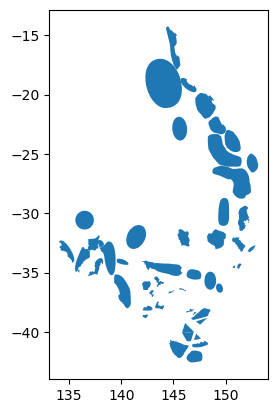

In [86]:
rez_gpd.plot()

### Define WA grid regions

No REZs, so use 100km buffer around transmission lines.

In [88]:
FILEPATH = "/g/data/ng72/dr6273/work/projects/wind_drought/data/"

In [89]:
gdf = geopandas.read_file(
    FILEPATH + "Electricity_Transmission_Lines/Electricity_Transmission_Lines.shp"
)

In [90]:
print(gdf.crs)

GEOGCS["GCS_GDA2020",DATUM["Geocentric_Datum_of_Australia_2020",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","1168"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433],AXIS["Longitude",EAST],AXIS["Latitude",NORTH]]


In [91]:
# Reproject to a metric CRS (metres)
# Use an appropriate UTM zone for your data
# Automatically estimate UTM from your geometries:
utm_crs = gdf.estimate_utm_crs()
print(f"Using UTM projection: {utm_crs}")
gdf_proj = gdf.to_crs(utm_crs)

Using UTM projection: EPSG:32753


In [92]:
# Buffer 100 km = 100,000 metres
gdf_proj["geometry"] = gdf_proj.buffer(100_000)

In [93]:
# Merge
gdf_proj = gdf_proj.dissolve()

In [94]:
# Reproject to EPSG:4326 (lat/lon)
gdf_out = gdf_proj.to_crs("EPSG:4326")

<Axes: >

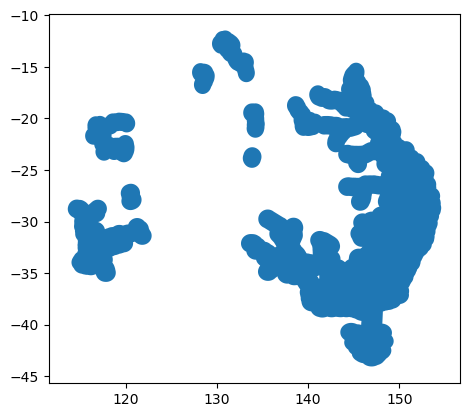

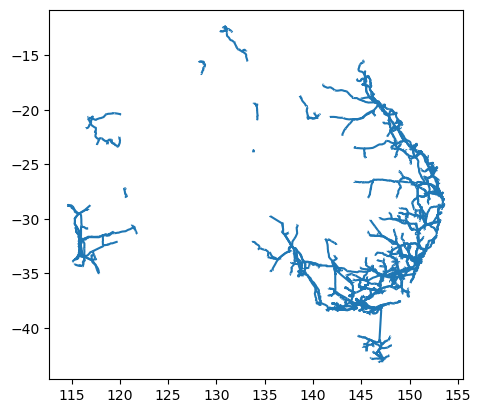

In [99]:
gdf_out.plot()
gdf.plot()

In [101]:
from shapely.geometry import box
from shapely.ops import unary_union

lines = gdf_out.to_crs("EPSG:4326")
min_lon, min_lat, max_lon, max_lat = lines.total_bounds

# SWIS: union of the two areas retained by the original mask conditions
swis_area = unary_union([
    box(min_lon, min_lat, 125, -29),
    box(min_lon, min_lat, 119, -25),
])

# NWIS: lat > -25 and lon < 122
nwis_area = box(min_lon, -25, 122, max_lat)

swis_lines = geopandas.clip(lines, swis_area)
nwis_lines = geopandas.clip(lines, nwis_area)

# Optional: make one dissolved geometry for each region
swis_region = swis_lines.geometry.union_all()
nwis_region = nwis_lines.geometry.union_all()

In [107]:
def to_file(polygon, name):
    
    if polygon.geom_type == "Polygon":
        polygon = MultiPolygon([polygon])
    
    gdf = geopandas.GeoDataFrame(
        {"region": [name]},
        geometry=[polygon],
        crs=lines.crs,
    )
    
    gdf.to_file(
        "data/" + name + "_transmission_region.shp",
        driver="ESRI Shapefile",
        engine="pyogrio",
        promote_to_multi=True,
    )

In [108]:
to_file(swis_region, "SWIS")

In [109]:
to_file(nwis_region, "NWIS")